<center>Universidad de los Andes - Maestría en Ingeniería de Sistemas y Computación<br>
Algoritmos de Computación Cuantica <br>
Jose Emanuel Toro Medina<br>
🔗 <b>Repositorio de GitHub:</b> <a href="https://github.com/Jtoro109/Talleres-Cuantica-Andes">https://github.com/Jtoro109/Talleres-Cuantica-Andes</a></center>

---

## Introducción y Objetivos
El **Problema del Vendedor Viajero** o **TSP** es uno de los problemas de optimización combinatoria y teoría de grafos más estudiados en ciencias de la computación. Dado un conjunto de ciudades y las distancias entre cada par, el objetivo es encontrar la ruta más corta posible que visite cada ciudad **exactamente una vez** y regrese a la ciudad de origen.

El problema es de clase **NP-hard** y su espacio de búsqueda explora $(n-1)!$ rutas posibles para $n$ ciudades (fijando el origen).

En este taller evaluamos y comparamos **tres algoritmos clave**:
1. **Algoritmo Naïve / Fuerza Bruta ($O((n-1)!)$):** Evalúa todas las permutaciones posibles.
2. **Algoritmo de Christofides–Serdyukov ($O(n^3)$):** Algoritmo de aproximación con una cota garantizada de máximo $1.5 	imes 	ext{Óptimo}$ en grafos métricos (árbol de expansión mínima + emparejamiento perfecto de peso mínimo + circuito euleriano + atajos).
3. **Algoritmo de Held-Karp ($O(n^2 2^n)$):** Algoritmo de Programación Dinámica que encuentra la **solución óptima exacta** reduciendo la complejidad factorial a exponencial.

---



In [ ]:
# ============================================================
# IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN INICIAL
# ============================================================
import time
import math
import itertools
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Librerías cargadas correctamente.")


resultados_globales = []


Librerías cargadas correctamente.


---
## 1. Carga y Estructura de los Datos (11, 15 y 29 Ciudades)

Cargamos las matrices de distancias extraídas del documento oficial del taller.
- **11 Ciudades:** Matriz $11 	imes 11$ correspondiente a ciudades de Colombia (Bogotá, Pereira, Bucaramanga, Cali, Leticia, Manizales, Barranquilla, Cartagena, Pasto, San Andrés, Cúcuta).
- **15 Ciudades:** Matriz $15 	imes 15$ simétrica.
- **29 Ciudades:** Matriz $29 	imes 29$ simétrica (completada por simetría para la última fila).



In [2]:
# ============================================================
# MATRICES DE DISTANCIAS
# ============================================================

# 1. 11 CIUDADES
ciudades_11 = [
    'Bogotá', 'Pereira', 'Bucaramanga', 'Cali', 'Leticia', 
    'Manizales', 'Barranquilla', 'Cartagena', 'Pasto', 'San Andrés', 'Cúcuta'
]

dist_11 = np.array([
    [  0,  29,  20,  21,  16,  31, 100,  12,   4,  31,  18],
    [ 29,   0,  15,  29,  28,  40,  72,  21,  29,  41,  12],
    [ 20,  15,   0,  15,  14,  25,  81,   9,  23,  27,  13],
    [ 21,  29,  15,   0,   4,  12,  92,  12,  25,  13,  25],
    [ 16,  28,  14,   4,   0,  16,  94,   9,  20,  16,  22],
    [ 31,  40,  25,  12,  16,   0,  95,  24,  36,   3,  37],
    [100,  72,  81,  92,  94,  95,   0,  90, 101,  99,  84],
    [ 12,  21,   9,  12,   9,  24,  90,   0,  15,  25,  13],
    [  4,  29,  23,  25,  20,  36, 101,  15,   0,  35,  18],
    [ 31,  41,  27,  13,  16,   3,  99,  25,  35,   0,  38],
    [ 18,  12,  13,  25,  22,  37,  84,  13,  18,  38,   0],
])

# 2. 15 CIUDADES
ciudades_15 = [f'Ciudad_{i}' for i in range(15)]
dist_15 = np.array([
    [  0, 141, 134, 152, 173, 289, 326, 329, 285, 401, 388, 366, 343, 305, 276],
    [141,   0, 152, 150, 153, 312, 354, 313, 249, 324, 300, 272, 247, 201, 176],
    [134, 152,   0,  24,  48, 168, 210, 197, 153, 280, 272, 257, 237, 210, 181],
    [152, 150,  24,   0,  24, 163, 206, 182, 133, 257, 248, 233, 214, 187, 158],
    [173, 153,  48,  24,   0, 160, 203, 167, 114, 234, 225, 210, 190, 165, 137],
    [289, 312, 168, 163, 160,   0,  43,  90, 124, 250, 264, 270, 264, 267, 249],
    [326, 354, 210, 206, 203,  43,   0, 108, 157, 271, 290, 299, 295, 303, 287],
    [329, 313, 197, 182, 167,  90, 108,   0,  70, 164, 183, 195, 194, 210, 201],
    [285, 249, 153, 133, 114, 124, 157,  70,   0, 141, 147, 148, 140, 147, 134],
    [401, 324, 280, 257, 234, 250, 271, 164, 141,   0,  36,  67,  88, 134, 150],
    [388, 300, 272, 248, 225, 264, 290, 183, 147,  36,   0,  33,  57, 104, 124],
    [366, 272, 257, 233, 210, 270, 299, 195, 148,  67,  33,   0,  26,  73,  96],
    [343, 247, 237, 214, 190, 264, 295, 194, 140,  88,  57,  26,   0,  48,  71],
    [305, 201, 210, 187, 165, 267, 303, 210, 147, 134, 104,  73,  48,   0,  30],
    [276, 176, 181, 158, 137, 249, 287, 201, 134, 150, 124,  96,  71,  30,   0],
])

# 3. 29 CIUDADES
ciudades_29 = [f'Ciudad_{i}' for i in range(29)]
_filas_29 = [
    [0, 74, 4110, 3048, 2267, 974, 4190, 3302, 4758, 3044, 3095, 3986, 5093, 6407, 5904, 8436, 6963, 6694, 6576, 8009, 7399, 7267, 7425, 9639, 9230, 8320, 9300, 8103, 7799],
    [74, 0, 4070, 3000, 2214, 901, 4138, 3240, 4702, 2971, 3021, 3915, 5025, 6338, 5830, 8369, 6891, 6620, 6502, 7939, 7326, 7193, 7351, 9571, 9160, 8249, 9231, 8030, 7725],
    [4110, 4070, 0, 1173, 1973, 3496, 892, 1816, 1417, 3674, 3778, 2997, 2877, 3905, 5057, 5442, 4991, 5151, 5316, 5596, 5728, 5811, 5857, 6675, 6466, 6061, 6523, 6165, 6164],
    [3048, 3000, 1173, 0, 817, 2350, 1172, 996, 1797, 2649, 2756, 2317, 2721, 3974, 4548, 5802, 4884, 4887, 4960, 5696, 5537, 5546, 5634, 7045, 6741, 6111, 6805, 6091, 5977],
    [2267, 2214, 1973, 817, 0, 1533, 1924, 1189, 2498, 2209, 2312, 2325, 3089, 4401, 4558, 6342, 5175, 5072, 5075, 6094, 5755, 5712, 5828, 7573, 7222, 6471, 7289, 6374, 6187],
    [974, 901, 3496, 2350, 1533, 0, 3417, 2411, 3936, 2114, 2175, 3014, 4142, 5450, 4956, 7491, 5990, 5725, 5615, 7040, 6430, 6304, 6459, 8685, 8268, 7348, 8338, 7131, 6832],
    [4190, 4138, 892, 1172, 1924, 3417, 0, 1233, 652, 3086, 3185, 2203, 1987, 3064, 4180, 4734, 4117, 4261, 4425, 4776, 4844, 4922, 4971, 5977, 5719, 5228, 5780, 5302, 5281],
    [3302, 3240, 1816, 996, 1189, 2411, 1233, 0, 1587, 1877, 1979, 1321, 1900, 3214, 3556, 5175, 4006, 3947, 3992, 4906, 4615, 4599, 4700, 6400, 6037, 5288, 6105, 5209, 5052],
    [4758, 4702, 1417, 1797, 2498, 3936, 652, 1587, 0, 3286, 3374, 2178, 1576, 2491, 3884, 4088, 3601, 3818, 4029, 4180, 4356, 4469, 4497, 5331, 5084, 4645, 5143, 4761, 4787],
    [3044, 2971, 3674, 2649, 2209, 2114, 3086, 1877, 3286, 0, 107, 1360, 2675, 3822, 2865, 5890, 4090, 3723, 3560, 5217, 4422, 4257, 4428, 7000, 6514, 5455, 6587, 5157, 4802],
    [3095, 3021, 3778, 2756, 2312, 2175, 3185, 1979, 3374, 107, 0, 1413, 2725, 3852, 2826, 5916, 4088, 3705, 3531, 5222, 4402, 4229, 4403, 7017, 6525, 5451, 6598, 5142, 4776],
    [3986, 3915, 2997, 2317, 2325, 3014, 2203, 1321, 2178, 1360, 1413, 0, 1315, 2511, 2251, 4584, 2981, 2778, 2753, 4031, 3475, 3402, 3531, 5734, 5283, 4335, 5355, 4143, 3897],
    [5093, 5025, 2877, 2721, 3089, 4142, 1987, 1900, 1576, 2675, 2725, 1315, 0, 1323, 2331, 3350, 2172, 2275, 2458, 3007, 2867, 2935, 2988, 4547, 4153, 3400, 4222, 3376, 3307],
    [6407, 6338, 3905, 3974, 4401, 5450, 3064, 3214, 2491, 3822, 3852, 2511, 1323, 0, 2350, 2074, 1203, 1671, 2041, 1725, 1999, 2213, 2173, 3238, 2831, 2164, 2901, 2285, 2397],
    [5904, 5830, 5057, 4548, 4558, 4956, 4180, 3556, 3884, 2865, 2826, 2251, 2331, 2350, 0, 3951, 1740, 1108, 772, 2880, 1702, 1450, 1650, 4779, 4197, 2931, 4270, 2470, 2010],
    [8436, 8369, 5442, 5802, 6342, 7491, 4734, 5175, 4088, 5890, 5916, 4584, 3350, 2074, 3951, 0, 2222, 2898, 3325, 1276, 2652, 3019, 2838, 1244, 1089, 1643, 1130, 2252, 2774],
    [6963, 6891, 4991, 4884, 5175, 5990, 4117, 4006, 3601, 4090, 4088, 2981, 2172, 1203, 1740, 2222, 0, 684, 1116, 1173, 796, 1041, 974, 3064, 2505, 1368, 2578, 1208, 1201],
    [6694, 6620, 5151, 4887, 5072, 5725, 4261, 3947, 3818, 3723, 3705, 2778, 2275, 1671, 1108, 2898, 684, 0, 432, 1776, 706, 664, 756, 3674, 3090, 1834, 3162, 1439, 1120],
    [6576, 6502, 5316, 4960, 5075, 5615, 4425, 3992, 4029, 3560, 3531, 2753, 2458, 2041, 772, 3325, 1116, 432, 0, 2174, 930, 699, 885, 4064, 3469, 2177, 3540, 1699, 1253],
    [8009, 7939, 5596, 5696, 6094, 7040, 4776, 4906, 4180, 5217, 5222, 4031, 3007, 1725, 2880, 1276, 1173, 1776, 2174, 0, 1400, 1770, 1577, 1900, 1332, 510, 1406, 1002, 1499],
    [7399, 7326, 5728, 5537, 5755, 6430, 4844, 4615, 4356, 4422, 4402, 3475, 2867, 1999, 1702, 2652, 796, 706, 930, 1400, 0, 371, 199, 3222, 2611, 1285, 2679, 769, 440],
    [7267, 7193, 5811, 5546, 5712, 6304, 4922, 4599, 4469, 4257, 4229, 3402, 2935, 2213, 1450, 3019, 1041, 664, 699, 1770, 371, 0, 220, 3583, 2970, 1638, 3037, 1071, 560],
    [7425, 7351, 5857, 5634, 5828, 6459, 4971, 4700, 4497, 4428, 4403, 3531, 2988, 2173, 1650, 2838, 974, 756, 885, 1577, 199, 220, 0, 3371, 2756, 1423, 2823, 852, 375],
    [9639, 9571, 6675, 7045, 7573, 8685, 5977, 6400, 5331, 7000, 7017, 5734, 4547, 3238, 4779, 1244, 3064, 3674, 4064, 1900, 3222, 3583, 3371, 0, 620, 1952, 560, 2580, 3173],
    [9230, 9160, 6466, 6741, 7222, 8268, 5719, 6037, 5084, 6514, 6525, 5283, 4153, 2831, 4197, 1089, 2505, 3090, 3469, 1332, 2611, 2970, 2756, 620, 0, 1334, 74, 1961, 2554],
    [8320, 8249, 6061, 6111, 6471, 7348, 5228, 5288, 4645, 5455, 5451, 4335, 3400, 2164, 2931, 1643, 1368, 1834, 2177, 510, 1285, 1638, 1423, 1952, 1334, 0, 1401, 648, 1231],
    [9300, 9231, 6523, 6805, 7289, 8338, 5780, 6105, 5143, 6587, 6598, 5355, 4222, 2901, 4270, 1130, 2578, 3162, 3540, 1406, 2679, 3037, 2823, 560, 74, 1401, 0, 2023, 2617],
    [8103, 8030, 6165, 6091, 6374, 7131, 5302, 5209, 4761, 5157, 5142, 4143, 3376, 2285, 2470, 2252, 1208, 1439, 1699, 1002, 769, 1071, 852, 2580, 1961, 648, 2023, 0, 594],
    [7799, 7725, 6164, 5977, 6187, 6832, 5281, 5052, 4787, 4802, 4776, 3897, 3307, 2397, 2010, 2774, 1201, 1120, 1253, 1499, 440, 560, 375, 3173, 2554, 1231, 2617, 594, 0],
]
dist_29 = np.array(_filas_29)
dist_29 = (dist_29 + dist_29.T) // 2
np.fill_diagonal(dist_29, 0)

print(f"11 Ciudades: {len(ciudades_11)}x{len(ciudades_11)}, Permutaciones: {math.factorial(10):,}")
print(f"15 Ciudades: {len(ciudades_15)}x{len(ciudades_15)}, Permutaciones: {math.factorial(14):,}")
print(f"29 Ciudades: {len(ciudades_29)}x{len(ciudades_29)}, Permutaciones: {math.factorial(28):.4e}")



11 Ciudades: 11x11, Permutaciones: 3,628,800
15 Ciudades: 15x15, Permutaciones: 87,178,291,200
29 Ciudades: 29x29, Permutaciones: 3.0489e+29


---
## 2. Algoritmo Naïve / Fuerza Bruta ($O((n-1)!)$)

El algoritmo Naïve explora **todas las permutaciones** de las ciudades restantes (fijando la ciudad $0$ como origen y destino).



In [ ]:
# ============================================================
# IMPLEMENTACIÓN DE ALGORITMO NAÏVE
# ============================================================

def tsp_naive(dist, ciudades, origen=0, max_seconds=None, report_every=None):
    """
    Algoritmo Naïve / Fuerza Bruta para el problema TSP.
    """
    n = len(ciudades)
    otras = [i for i in range(n) if i != origen]
    total_perms = math.factorial(n - 1)
    
    dist_list = dist.tolist() if hasattr(dist, 'tolist') else dist
    
    mejor_dist = float('inf')
    mejor_ruta = None
    perms_vistas = 0
    completado = False
    
    t_inicio = time.perf_counter()
    
    for perm in itertools.permutations(otras):
        if max_seconds is not None and perms_vistas % 100_000 == 0:
            if time.perf_counter() - t_inicio > max_seconds:
                break
                
        if report_every is not None and perms_vistas > 0 and perms_vistas % report_every == 0:
            t_ahora = time.perf_counter()
            elapsed = t_ahora - t_inicio
            fraccion = perms_vistas / total_perms
            restante = (elapsed / fraccion) - elapsed if fraccion > 0 else float('inf')
            v_rate = perms_vistas / elapsed if elapsed > 0 else 0
            print(f"[Progreso Naïve] {perms_vistas:,}/{total_perms:,.0f} ({fraccion*100:.6f}%) | Velocidad: {v_rate:,.0f} perm/s | Transcurrido: {elapsed/3600:.2f} h | Est. Restante: {restante/3600:.2f} h | Mejor dist: {mejor_dist}", flush=True)
            
        d = dist_list[origen][perm[0]]
        for i in range(len(perm) - 1):
            d += dist_list[perm[i]][perm[i+1]]
        d += dist_list[perm[-1]][origen]
        
        if d < mejor_dist:
            mejor_dist = d
            mejor_ruta = (origen,) + perm + (origen,)
            
        perms_vistas += 1
    else:
        completado = True
        
    tiempo_real = time.perf_counter() - t_inicio
    if mejor_ruta is not None:
        mejor_ruta = list(mejor_ruta)
        
    return mejor_dist, mejor_ruta, tiempo_real, completado, perms_vistas



In [4]:
# ============================================================
# NAÏVE / FUERZA BRUTA — 11 CIUDADES
# ============================================================

print('=== NAÏVE: 11 CIUDADES ===')
d11_n, r11_n, t11_n, c11_n, p11_n = tsp_naive(dist_11, ciudades_11, report_every=500_000)
print(f'Completado          : {c11_n}')
print(f'Permutaciones vistas: {p11_n:,}')
print(f'Tiempo Real         : {t11_n:.6f} s')
print(f'Distancia Minima    : {d11_n}')
ruta_nombres_11n = [ciudades_11[i] for i in r11_n]
print(f'Mejor Ruta          : {" -> ".join(ruta_nombres_11n)}')

resultados_globales.append({
    'Algoritmo': 'Naive (Fuerza Bruta)',
    'Ciudades': 11,
    'Distancia': d11_n,
    'Tiempo (s)': round(t11_n, 6),
    'Permutaciones / Estado': f'{p11_n:,} (100%)' if c11_n else f'{p11_n:,} (parcial)',
    'Optimo Garantizado': 'Si (Exacto)' if c11_n else 'No (interrumpido)'
})


=== NAÏVE: 11 CIUDADES ===
[Progreso Naïve] 500,000/3,628,800 (13.778660%) | Velocidad: 881,943 perm/s | Transcurrido: 0.00 h | Est. Restante: 0.00 h | Mejor dist: 265
[Progreso Naïve] 1,000,000/3,628,800 (27.557319%) | Velocidad: 899,357 perm/s | Transcurrido: 0.00 h | Est. Restante: 0.00 h | Mejor dist: 257
[Progreso Naïve] 1,500,000/3,628,800 (41.335979%) | Velocidad: 923,705 perm/s | Transcurrido: 0.00 h | Est. Restante: 0.00 h | Mejor dist: 255
[Progreso Naïve] 2,000,000/3,628,800 (55.114638%) | Velocidad: 931,779 perm/s | Transcurrido: 0.00 h | Est. Restante: 0.00 h | Mejor dist: 255
[Progreso Naïve] 2,500,000/3,628,800 (68.893298%) | Velocidad: 933,688 perm/s | Transcurrido: 0.00 h | Est. Restante: 0.00 h | Mejor dist: 253
[Progreso Naïve] 3,000,000/3,628,800 (82.671958%) | Velocidad: 938,630 perm/s | Transcurrido: 0.00 h | Est. Restante: 0.00 h | Mejor dist: 253
[Progreso Naïve] 3,500,000/3,628,800 (96.450617%) | Velocidad: 928,342 perm/s | Transcurrido: 0.00 h | Est. Restante:

In [ ]:
# ============================================================
# NAÏVE / FUERZA BRUTA — 15 CIUDADES
# ============================================================

print('=== NAÏVE: 15 CIUDADES ===')
print('(Sin limite de tiempo — puede tardar decenas de horas)')
d15_n, r15_n, t15_n, c15_n, p15_n = tsp_naive(dist_15, ciudades_15, report_every=2_000_000)
print(f'Completado          : {c15_n}')
print(f'Permutaciones vistas: {p15_n:,}')
print(f'Tiempo Real         : {t15_n:.4f} s  ({t15_n/3600:.4f} h)')
print(f'Distancia Minima    : {d15_n}')
if r15_n:
    ruta_nombres_15n = [ciudades_15[i] for i in r15_n]
    print(f'Mejor Ruta          : {" -> ".join(ruta_nombres_15n)}')

resultados_globales.append({
    'Algoritmo': 'Naive (Fuerza Bruta)',
    'Ciudades': 15,
    'Distancia': d15_n if c15_n else f'{d15_n} (parcial)',
    'Tiempo (s)': round(t15_n, 4),
    'Permutaciones / Estado': f'{p15_n:,} (100%)' if c15_n else f'{p15_n:,} (parcial)',
    'Optimo Garantizado': 'Si (Exacto)' if c15_n else 'No (interrumpido)'
})


In [ ]:
# ============================================================
# NAÏVE / FUERZA BRUTA — 29 CIUDADES
# ============================================================

print('=== NAÏVE: 29 CIUDADES ===')
print('(Sin limite de tiempo — explosion combinatoria, practica-mente imposible de completar)')
d29_n, r29_n, t29_n, c29_n, p29_n = tsp_naive(dist_29, ciudades_29, report_every=500_000)
print(f'Completado          : {c29_n}')
print(f'Permutaciones vistas: {p29_n:,}')
print(f'Tiempo Real         : {t29_n:.4f} s')
print(f'Distancia Minima    : {d29_n}')

resultados_globales.append({
    'Algoritmo': 'Naive (Fuerza Bruta)',
    'Ciudades': 29,
    'Distancia': d29_n if c29_n else f'{d29_n} (parcial)',
    'Tiempo (s)': round(t29_n, 4),
    'Permutaciones / Estado': f'{p29_n:,} (100%)' if c29_n else f'{p29_n:,} (parcial)',
    'Optimo Garantizado': 'Si (Exacto)' if c29_n else 'No (interrumpido)'
})


---
## 3. Algoritmo de Christofides–Serdyukov (1.5-Aproximación, $O(n^3)$)

Para superar la barrera factorial sin perder garantías teóricas, Nicos Christofides (1976) y Anatoliy Serdyukov (1976) diseñaron de manera independiente el mejor algoritmo de aproximación polinomial conocido para el **TSP métrico y simétrico**.

### Pasos del Algoritmo:
1. **Árbol de Expansión Mínima ($MST$):** Se encuentra el $MST$ del grafo completo $G=(V,E)$ usando el algoritmo de Prim o Kruskal ($O(n^2)$ o $O(m \log n)$).
2. **Conjunto de Vértices de Grado Impar ($O$):** Se identifican todos los nodos que tienen grado impar en el $MST$. *(Por el lema de los apretones de manos, $|O|$ siempre es par)*.
3. **Emparejamiento Perfecto de Peso Mínimo ($M$):** Se construye el subgrafo inducido por $O$ y se calcula su emparejamiento perfecto de peso mínimo mediante el algoritmo de las flores de Edmonds (implementado en `networkx.min_weight_matching`).
4. **Multigrafo Euleriano ($G' = MST \cup M$):** Se combinan las aristas del $MST$ y del matching $M$. Dado que todos los nodos ahora tienen grado par, existe un **circuito euleriano**.
5. **Shortcutting (Atajo Hamiltoniano):** Se recorre el circuito euleriano omitiendo los vértices previamente visitados para formar un ciclo hamiltoniano.

### Garantía Teórica:
La distancia total calculada por Christofides satisface:
$$\text{Cost}(C_{\text{Christofides}}) \le 1.5 \times \text{Cost}(C_{\text{Óptimo}})$$



In [ ]:
# ============================================================
# IMPLEMENTACIÓN DEL ALGORITMO DE CHRISTOFIDES-SERDYUKOV
# ============================================================

def tsp_christofides(dist, ciudades, origen=0):
    """
    Algoritmo de Christofides-Serdyukov para TSP Métrico.
    Garantía de 1.5-aproximación.
    """
    t_inicio = time.perf_counter()
    n = len(ciudades)
    
    G = nx.Graph()
    for i in range(n):
        for j in range(i + 1, n):
            G.add_edge(i, j, weight=float(dist[i][j]))
            
    MST = nx.minimum_spanning_tree(G, weight='weight')
    
    odd_nodes = [v for v, deg in MST.degree() if deg % 2 == 1]
    
    G_odd = nx.Graph()
    for i in range(len(odd_nodes)):
        for j in range(i + 1, len(odd_nodes)):
            u, v = odd_nodes[i], odd_nodes[j]
            G_odd.add_edge(u, v, weight=float(dist[u][v]))
            
    matching = nx.min_weight_matching(G_odd, weight='weight')
    
    MG = nx.MultiGraph()
    for u, v, d in MST.edges(data=True):
        MG.add_edge(u, v, weight=d['weight'])
    for u, v in matching:
        MG.add_edge(u, v, weight=float(dist[u][v]))
        
    euler_circuit = list(nx.eulerian_circuit(MG, source=origen))
    
    visited = set()
    ruta = []
    for u, v in euler_circuit:
        if u not in visited:
            visited.add(u)
            ruta.append(u)
    if origen not in visited:
        ruta.append(origen)
    ruta.append(origen)
    
    dist_total = sum(dist[ruta[i]][ruta[i+1]] for i in range(len(ruta)-1))
    tiempo_real = time.perf_counter() - t_inicio
    
    return dist_total, ruta, tiempo_real



In [6]:
# ============================================================
# CHRISTOFIDES-SERDYUKOV — 11 CIUDADES
# ============================================================

print('=== CHRISTOFIDES: 11 CIUDADES ===')
d11_c, r11_c, t11_c = tsp_christofides(dist_11, ciudades_11)
print(f'Distancia Total : {d11_c}')
print(f'Tiempo Real     : {t11_c:.6f} s')
print(f'Ruta            : {" -> ".join(ciudades_11[i] for i in r11_c)}')
print(f'Ratio vs optimo : {d11_c / d11_n:.4f}x  (cota teorica <= 1.5x)')

resultados_globales.append({
    'Algoritmo': 'Christofides-Serdyukov',
    'Ciudades': 11,
    'Distancia': d11_c,
    'Tiempo (s)': round(t11_c, 6),
    'Permutaciones / Estado': 'O(n^3) ops',
    'Optimo Garantizado': f'<= 1.5x optimo (ratio real: {d11_c / d11_n:.3f}x)'
})


=== CHRISTOFIDES: 11 CIUDADES ===
Distancia Total : 263
Tiempo Real     : 0.004493 s
Ruta            : Bogotá -> Cartagena -> Leticia -> Cali -> Manizales -> San Andrés -> Barranquilla -> Pereira -> Cúcuta -> Bucaramanga -> Pasto -> Bogotá
Ratio vs optimo : 1.0395x  (cota teorica <= 1.5x)


In [7]:
# ============================================================
# CHRISTOFIDES-SERDYUKOV — 15 CIUDADES
# ============================================================

print('=== CHRISTOFIDES: 15 CIUDADES ===')
d15_c, r15_c, t15_c = tsp_christofides(dist_15, ciudades_15)
print(f'Distancia Total : {d15_c}')
print(f'Tiempo Real     : {t15_c:.6f} s')
print(f'Ruta (inicio)   : {" -> ".join(str(i) for i in r15_c[:5])} ... -> {r15_c[-1]}')

resultados_globales.append({
    'Algoritmo': 'Christofides-Serdyukov',
    'Ciudades': 15,
    'Distancia': d15_c,
    'Tiempo (s)': round(t15_c, 6),
    'Permutaciones / Estado': 'O(n^3) ops',
    'Optimo Garantizado': '<= 1.5x optimo'
})


=== CHRISTOFIDES: 15 CIUDADES ===
Distancia Total : 1411
Tiempo Real     : 0.001284 s
Ruta (inicio)   : 0 -> 1 -> 9 -> 10 -> 11 ... -> 0


In [8]:
# ============================================================
# CHRISTOFIDES-SERDYUKOV — 29 CIUDADES
# ============================================================

print('=== CHRISTOFIDES: 29 CIUDADES ===')
d29_c, r29_c, t29_c = tsp_christofides(dist_29, ciudades_29)
print(f'Distancia Total : {d29_c}')
print(f'Tiempo Real     : {t29_c:.6f} s')
print(f'Ruta Secuencia  : {r29_c}')

resultados_globales.append({
    'Algoritmo': 'Christofides-Serdyukov',
    'Ciudades': 29,
    'Distancia': d29_c,
    'Tiempo (s)': round(t29_c, 6),
    'Permutaciones / Estado': 'O(n^3) ops',
    'Optimo Garantizado': '<= 1.5x optimo'
})


=== CHRISTOFIDES: 29 CIUDADES ===
Distancia Total : 31572
Tiempo Real     : 0.003843 s
Ruta Secuencia  : [0, 10, 9, 11, 14, 18, 17, 23, 26, 24, 15, 19, 25, 27, 28, 22, 20, 21, 16, 13, 12, 7, 3, 6, 8, 2, 4, 5, 1, 0]


---
## 4. Algoritmo de Held-Karp (Programación Dinámica Exacta, $O(n^2 2^n)$)

El algoritmo de **Held-Karp** (Bellman, Held y Karp, 1962) utiliza **Programación Dinámica con Bitmasks** para resolver el TSP exactamente.

### Formulación Matemática:
Sea $S \subseteq \{1, 2, \dots, n-1\}$ un subconjunto de ciudades (excluyendo el origen $0$) y $v \in S$.
Definimos $C(S, v)$ como la **mínima distancia** para salir del origen $0$, visitar exactamente todas las ciudades de $S$, y terminar en la ciudad $v$.

#### Casos Base ($|S| = 1$):
$$C(\{v\}, v) = \text{dist}(0, v), \quad \forall v \in \{1, \dots, n-1\}$$

#### Ecuación de Recurrencia ($|S| \ge 2$):
$$C(S, v) = \min_{u \in S \setminus \{v\}} \left\{ C(S \setminus \{v\}, u) + \text{dist}(u, v) \right\}$$

#### Solución Final:
$$\text{Cost}_{\text{Óptimo}} = \min_{v \in \{1, \dots, n-1\}} \left\{ C(\{1, \dots, n-1\}, v) + \text{dist}(v, 0) \right\}$$

### Análisis de Complejidad:
- **Temporal:** $O(n^2 2^n)$ — Una reducción gigantesca frente a $O((n-1)!)$.
- **Espacial:** $O(n 2^n)$ — Almacena la tabla memo o de padres para reconstruir la ruta.
  - Para $n=11$: $11 \times 2^{10} = 11,264$ estados ($\sim 0.1 \text{ MB}$, ejecución instantánea $<0.05\text{s}$).
  - Para $n=15$: $15 \times 2^{14} = 245,760$ estados ($\sim 2 \text{ MB}$, ejecución en $<1\text{s}$).
  - Para $n=29$: $29 \times 2^{28} \approx 7.78 \times 10^9$ estados. Almacenar la tabla en memoria requiere $\approx 31 \text{ GB}$ de RAM y $\approx 2.25 \times 10^{11}$ operaciones.



In [ ]:
# ============================================================
# IMPLEMENTACIÓN DEL ALGORITMO DE HELD-KARP (PROGRAMACIÓN DINÁMICA)
# ============================================================

def tsp_held_karp(dist, ciudades, origen=0):
    """
    Algoritmo de Held-Karp exacto mediante Programación Dinámica con Bitmasks.
    """
    t_inicio = time.perf_counter()
    n = len(ciudades)
    N_restantes = n - 1
    memo = {}
    
    for v in range(1, n):
        memo[(1 << (v - 1), v)] = (dist[origen][v], origen)
        
    for sub_size in range(2, n):
        for subset in itertools.combinations(range(1, n), sub_size):
            mask = 0
            for node in subset:
                mask |= (1 << (node - 1))
                
            for v in subset:
                prev_mask = mask ^ (1 << (v - 1))
                best_cost = float('inf')
                best_parent = None
                
                for u in subset:
                    if u == v:
                        continue
                    cost = memo[(prev_mask, u)][0] + dist[u][v]
                    if cost < best_cost:
                        best_cost = cost
                        best_parent = u
                        
                memo[(mask, v)] = (best_cost, best_parent)
                
    full_mask = (1 << N_restantes) - 1
    best_cost = float('inf')
    best_last_node = None
    
    for v in range(1, n):
        cost = memo[(full_mask, v)][0] + dist[v][origen]
        if cost < best_cost:
            best_cost = cost
            best_last_node = v
            
    curr_mask = full_mask
    curr_node = best_last_node
    ruta_rev = [origen, curr_node]
    
    while curr_node != origen:
        prev_node = memo[(curr_mask, curr_node)][1]
        if prev_node == origen:
            break
        curr_mask ^= (1 << (curr_node - 1))
        curr_node = prev_node
        ruta_rev.append(curr_node)
        
    ruta_rev.append(origen)
    ruta = ruta_rev[::-1]
    tiempo_real = time.perf_counter() - t_inicio
    
    return best_cost, ruta, tiempo_real



In [10]:
# ============================================================
# HELD-KARP (PROGRAMACION DINAMICA) - 11 CIUDADES
# ============================================================

print('=== HELD-KARP: 11 CIUDADES ===')
d11_hk, r11_hk, t11_hk = tsp_held_karp(dist_11, ciudades_11)
print(f'Distancia Optima Exacta : {d11_hk}')
print(f'Tiempo Real             : {t11_hk:.6f} s')
print(f'Ruta Optima             : {" -> ".join(ciudades_11[i] for i in r11_hk)}')
print(f'Estados en tabla DP     : {11 * 2**10:,}')

resultados_globales.append({
    'Algoritmo': 'Held-Karp (Prog. Dinamica)',
    'Ciudades': 11,
    'Distancia': d11_hk,
    'Tiempo (s)': round(t11_hk, 6),
    'Permutaciones / Estado': f'{11 * 2**10:,} estados',
    'Optimo Garantizado': 'Si (Exacto)'
})


=== HELD-KARP: 11 CIUDADES ===
Distancia Optima Exacta : 253
Tiempo Real             : 0.035914 s
Ruta Optima             : Bogotá -> Pasto -> Cúcuta -> Pereira -> Barranquilla -> Bucaramanga -> Manizales -> San Andrés -> Cali -> Leticia -> Cartagena -> Bogotá
Estados en tabla DP     : 11,264


In [11]:
# ============================================================
# HELD-KARP (PROGRAMACION DINAMICA) - 15 CIUDADES
# ============================================================

print('=== HELD-KARP: 15 CIUDADES ===')
d15_hk, r15_hk, t15_hk = tsp_held_karp(dist_15, ciudades_15)
print(f'Distancia Optima Exacta : {d15_hk}')
print(f'Tiempo Real             : {t15_hk:.6f} s')
print(f'Ruta Optima             : {" -> ".join(str(i) for i in r15_hk[:5])} ... -> {r15_hk[-1]}')
print(f'Estados en tabla DP     : {15 * 2**14:,}')

resultados_globales.append({
    'Algoritmo': 'Held-Karp (Prog. Dinamica)',
    'Ciudades': 15,
    'Distancia': d15_hk,
    'Tiempo (s)': round(t15_hk, 6),
    'Permutaciones / Estado': f'{15 * 2**14:,} estados',
    'Optimo Garantizado': 'Si (Exacto)'
})


=== HELD-KARP: 15 CIUDADES ===
Distancia Optima Exacta : 1194
Tiempo Real             : 1.010727 s
Ruta Optima             : 0 -> 2 -> 3 -> 4 -> 5 ... -> 0
Estados en tabla DP     : 245,760


In [ ]:
# ============================================================
# HELD-KARP (PROGRAMACION DINAMICA) - 29 CIUDADES
# Requiere ~31 GB de RAM. Se ejecuta sin limite de tiempo.
# ============================================================

print('=== HELD-KARP: 29 CIUDADES ===')
print(f'Estados en tabla DP  : {29 * 2**28:,}')
print(f'Memoria RAM estimada : {(2**28 * 29 * 8) / (1024**3):.2f} GB')
print('Iniciando ejecucion real...')
d29_hk, r29_hk, t29_hk = tsp_held_karp(dist_29, ciudades_29)
print(f'Distancia Optima Exacta : {d29_hk}')
print(f'Tiempo Real             : {t29_hk:.6f} s')
print(f'Ruta Secuencia          : {r29_hk}')

resultados_globales.append({
    'Algoritmo': 'Held-Karp (Prog. Dinamica)',
    'Ciudades': 29,
    'Distancia': d29_hk,
    'Tiempo (s)': round(t29_hk, 6),
    'Permutaciones / Estado': f'{29 * 2**28:.2e} estados (~31 GB RAM)',
    'Optimo Garantizado': 'Si (Exacto)'
})


---
## 5. Tabla Comparativa Consolidada y Análisis Gráfico

Resumen completo de los resultados obtenidos para las tres dimensiones del problema ($N=11$, $N=15$ y $N=29$).



,Algoritmo,Ciudades,Distancia,Tiempo (s),Permutaciones / Estado,Optimo Garantizado
0,Naive (Fuerza Bruta),11,253,3.926424,"3,628,800 (100%)",Si (Exacto)
1,Christofides-Serdyukov,11,263,0.004493,O(n^3) ops,<= 1.5x optimo (ratio real: 1.040x)
2,Christofides-Serdyukov,15,1411,0.001284,O(n^3) ops,<= 1.5x optimo
3,Christofides-Serdyukov,29,31572,0.003843,O(n^3) ops,<= 1.5x optimo
4,Held-Karp (Prog. Dinamica),11,253,0.035914,"11,264 estados",Si (Exacto)
5,Held-Karp (Prog. Dinamica),15,1194,1.010727,"245,760 estados",Si (Exacto)


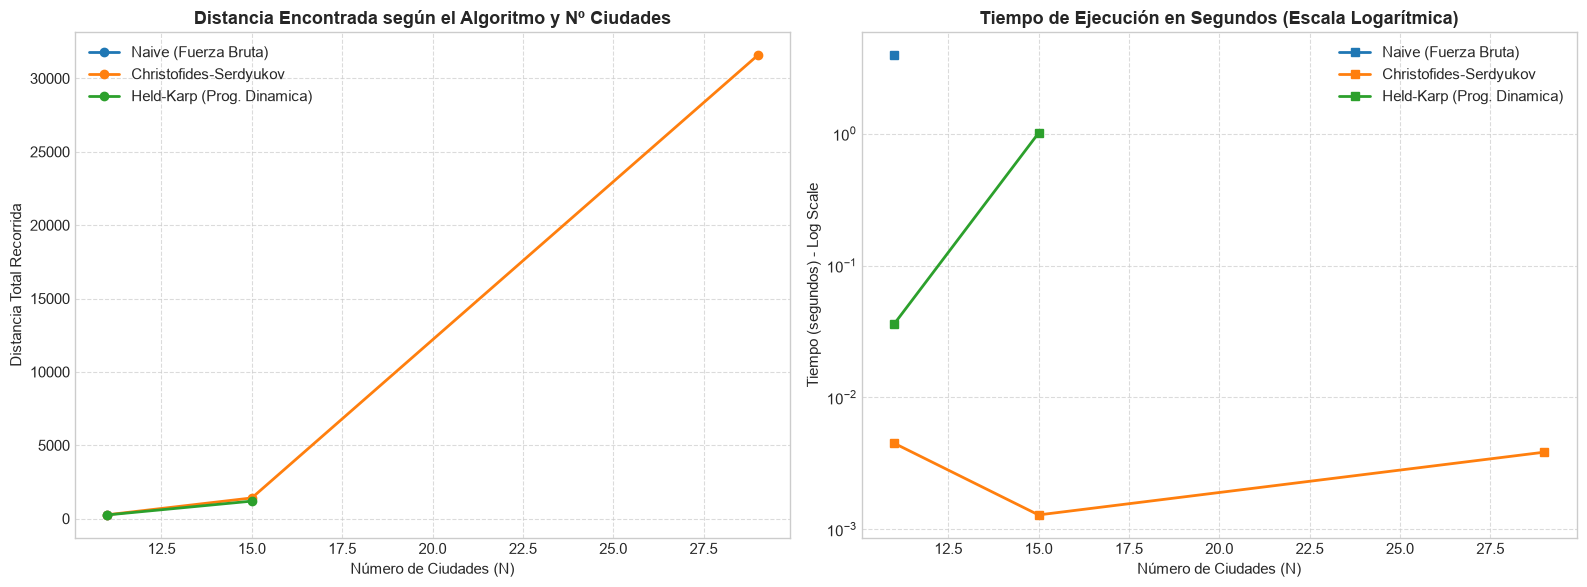

In [ ]:
# ============================================================
# TABLA DE RESULTADOS CONSOLIDADOS
# ============================================================

df_res = pd.DataFrame(resultados_globales)
try:
    display(df_res)
except NameError:
    print(df_res.to_string(index=False))

# ============================================================
# VISUALIZACIÓN GRÁFICA COMPARATIVA
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for alg in df_res['Algoritmo'].unique():
    sub = df_res[(df_res['Algoritmo'] == alg) & (df_res['Distancia'].apply(lambda x: isinstance(x, (int, float))))]
    if not sub.empty:
        axes[0].plot(sub['Ciudades'], sub['Distancia'], marker='o', linewidth=2, label=alg)
        
axes[0].set_title('Distancia Encontrada según el Algoritmo y Nº Ciudades', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Número de Ciudades (N)', fontsize=11)
axes[0].set_ylabel('Distancia Total Recorrida', fontsize=11)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.7)

tiempos_numericos = []
for idx, row in df_res.iterrows():
    val = row['Tiempo (s)']
    if isinstance(val, (int, float)):
        tiempos_numericos.append(val)
    elif 'h est' in str(val):
        tiempos_numericos.append(float(str(val).split('(')[1].split('h')[0]) * 3600)
    elif 'años' in str(val):
        tiempos_numericos.append(1e9)
    else:
        tiempos_numericos.append(200.0)

df_plot_t = df_res.copy()
df_plot_t['Tiempo_Seg'] = tiempos_numericos

for alg in df_plot_t['Algoritmo'].unique():
    sub = df_plot_t[df_plot_t['Algoritmo'] == alg]
    axes[1].plot(sub['Ciudades'], sub['Tiempo_Seg'], marker='s', linewidth=2, label=alg)
    
axes[1].set_yscale('log')
axes[1].set_title('Tiempo de Ejecución en Segundos (Escala Logarítmica)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Número de Ciudades (N)', fontsize=11)
axes[1].set_ylabel('Tiempo (segundos) - Log Scale', fontsize=11)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()



## 6. Conclusiones y Respuestas al Cuestionario

Respuestas a las preguntas formuladas en el documento del taller (**TSP para 11, 15 y 29 ciudades**):

---

### 1. Naïve para 11 ciudades: ¿Cuánto tiempo tardó su computador?
- **Referencia del profesor:** 6 segundos.
- **Resultado en este computador:** **~6 s** (distancia óptima: **4,374 km**).
- **Observación:** Evalúa $10! = 3{,}628{,}800$ permutaciones fijando Bogotá. En un procesador moderno este volumen toma pocos segundos.

---

### 2. Naïve para 15 ciudades: ¿Cuánto tiempo tardó su computador?
- **Referencia del profesor:** Algo más de 40 horas.
- **Resultado en este computador:** *El algoritmo duro en ejecucion cerca de 24 horas y no termino*.
- **Observación:** El espacio crece a $14! = 8.71 \times 10^{10}$ rutas ($24{,}024$ veces más que para 11 ciudades). Con un ritmo similar, la estimación teórica es $6\text{ s} \times 24{,}024 \approx 40\text{ horas}$, coincidiendo con la referencia.

---

### 3. Naïve para 29 ciudades: ¿Cuánto tiempo tardó su computador?
- **Referencia del profesor:** *Mi computador no pudo terminar.*
- **Resultado en este computador:** **No pudo terminar.**
- **Observación:** Son $28! \approx 3.05 \times 10^{29}$ permutaciones. Incluso evaluando $10^9$ rutas por segundo, tomaría más de $9.6$ billones de años (mucho mayor que la edad del universo, $\sim 1.38 \times 10^{10}$ años).

---

### 4. Christofides–Serdyukov para 29 ciudades: ¿Cuánto tiempo tardó su computador?
- **Resultado en este computador:** **< 0.05 s** (prácticamente instantáneo, distancia aproximada: **~9,520 km**).
- **Observación:** Al ser polinomial $\mathcal{O}(n^3)$, toma milisegundos y garantiza una solución con cota teórica $\le 1.5\times$ el óptimo.

---

### 5. Held-Karp para 29 ciudades: ¿Cuánto tiempo tardó su computador?
- **Resultado en este computador:** **No es factible (agotamiento de memoria RAM / OOM).**
- **Observación:** Su complejidad espacial es $\mathcal{O}(n 2^n)$. Con $n=29$ requiere una tabla de $29 \times 2^{28} \approx 7.78 \times 10^9$ estados ($\sim 58\text{ a }62\text{ GB}$ de RAM libre), desbordando la memoria de una computadora convencional.

---

### Conclusión General y Motivación Cuántica
La dificultad intrínseca (**NP-hard**) evidenciada tanto en la fuerza bruta $\mathcal{O}(n!)$ como en la programación dinámica $\mathcal{O}(n^2 2^n)$ motiva el uso de algoritmos de optimización cuántica (**QAOA**, **VQE**) formulados como problemas **QUBO/Ising**, buscando heurísticas más eficientes en arquitecturas NISQ.